# Phase 5 — Évaluation des prévisions

Comparaison des deux modèles à paramètres fixes. La cible est le rendement logarithmique quotidien au carré, approximation bruitée de la variance sous une hypothèse de moyenne conditionnelle proche de zéro.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
scores = pd.read_csv(ROOT / 'reports/phase5_scores.csv')
scores

,index,period,model,observations,mae,rmse
0,S&P 500,validation,Moving window (21),502,0.000069,0.000108
1,S&P 500,validation,EWMA (0.94),502,0.000069,0.000107
2,S&P 500,test,Moving window (21),420,0.000138,0.000478
3,S&P 500,test,EWMA (0.94),420,0.000133,0.000466
4,CAC 40,validation,Moving window (21),511,0.000075,0.000129
5,CAC 40,validation,EWMA (0.94),511,0.000073,0.000125
6,CAC 40,test,Moving window (21),428,0.000108,0.000234
7,CAC 40,test,EWMA (0.94),428,0.000107,0.000226
8,FTSE 100,validation,Moving window (21),505,0.000051,0.000102
9,FTSE 100,validation,EWMA (0.94),505,0.000050,0.000099


## 1. Calcul d’une erreur de prévision

La variance prévue est rapprochée du rendement au carré de sa date cible. Les calculs utilisent les unités de variance quotidienne, sans annualisation.

In [2]:
data = pd.read_csv(ROOT / 'data/evaluation/sp500_evaluation.csv', parse_dates=['target_date', 'forecast_origin'])
row = data.loc[(data.period == 'test') & data.eligible].iloc[0]
print('Forecast origin:', row.forecast_origin.date())
print('Target date:', row.target_date.date())
print('Squared return:', row.target_squared_return)
print('Moving-window forecast:', row.moving_window_variance)
print('Absolute error:', abs(row.moving_window_variance - row.target_squared_return))

Forecast origin: 2024-12-31
Target date: 2025-01-02
Squared return: 4.956692873224026e-06
Moving-window forecast: 7.948479481580983e-05
Absolute error: 7.45281019425858e-05


## 2. Calcul de la MAE et de la RMSE

La MAE est la moyenne des erreurs absolues. La RMSE est la racine carrée de la moyenne des erreurs au carré ; les grandes erreurs y ont davantage de poids.

In [3]:
test = data.loc[(data.period == 'test') & data.eligible]
errors = test.moving_window_variance - test.target_squared_return
mae = errors.abs().mean()
rmse = np.sqrt((errors**2).mean())
print('MAE:', mae, 'RMSE:', rmse)
saved = scores.loc[(scores['index']=='S&P 500') & (scores.period=='test') & (scores.model=='Moving window (21)')].iloc[0]
np.testing.assert_allclose([mae, rmse], [saved.mae, saved.rmse])

MAE: 0.00013814732937063204 RMSE: 0.000478215217801141


## 3. Dates communes d’évaluation

Les deux modèles utilisent un masque d’éligibilité commun par indice. Une date est retenue lorsque la cible et les deux prévisions sont disponibles.

In [4]:
pd.read_csv(ROOT / 'reports/phase5_coverage.csv')

,index,period,candidate_dates,scored_dates,excluded_dates
0,S&P 500,validation,502,502,0
1,S&P 500,test,420,420,0
2,CAC 40,validation,511,511,0
3,CAC 40,test,428,428,0
4,FTSE 100,validation,505,505,0
5,FTSE 100,test,424,424,0


## 4. Résultats sur la période de test

Les erreurs de variance sont remises à l’échelle pour la lisibilité des figures.

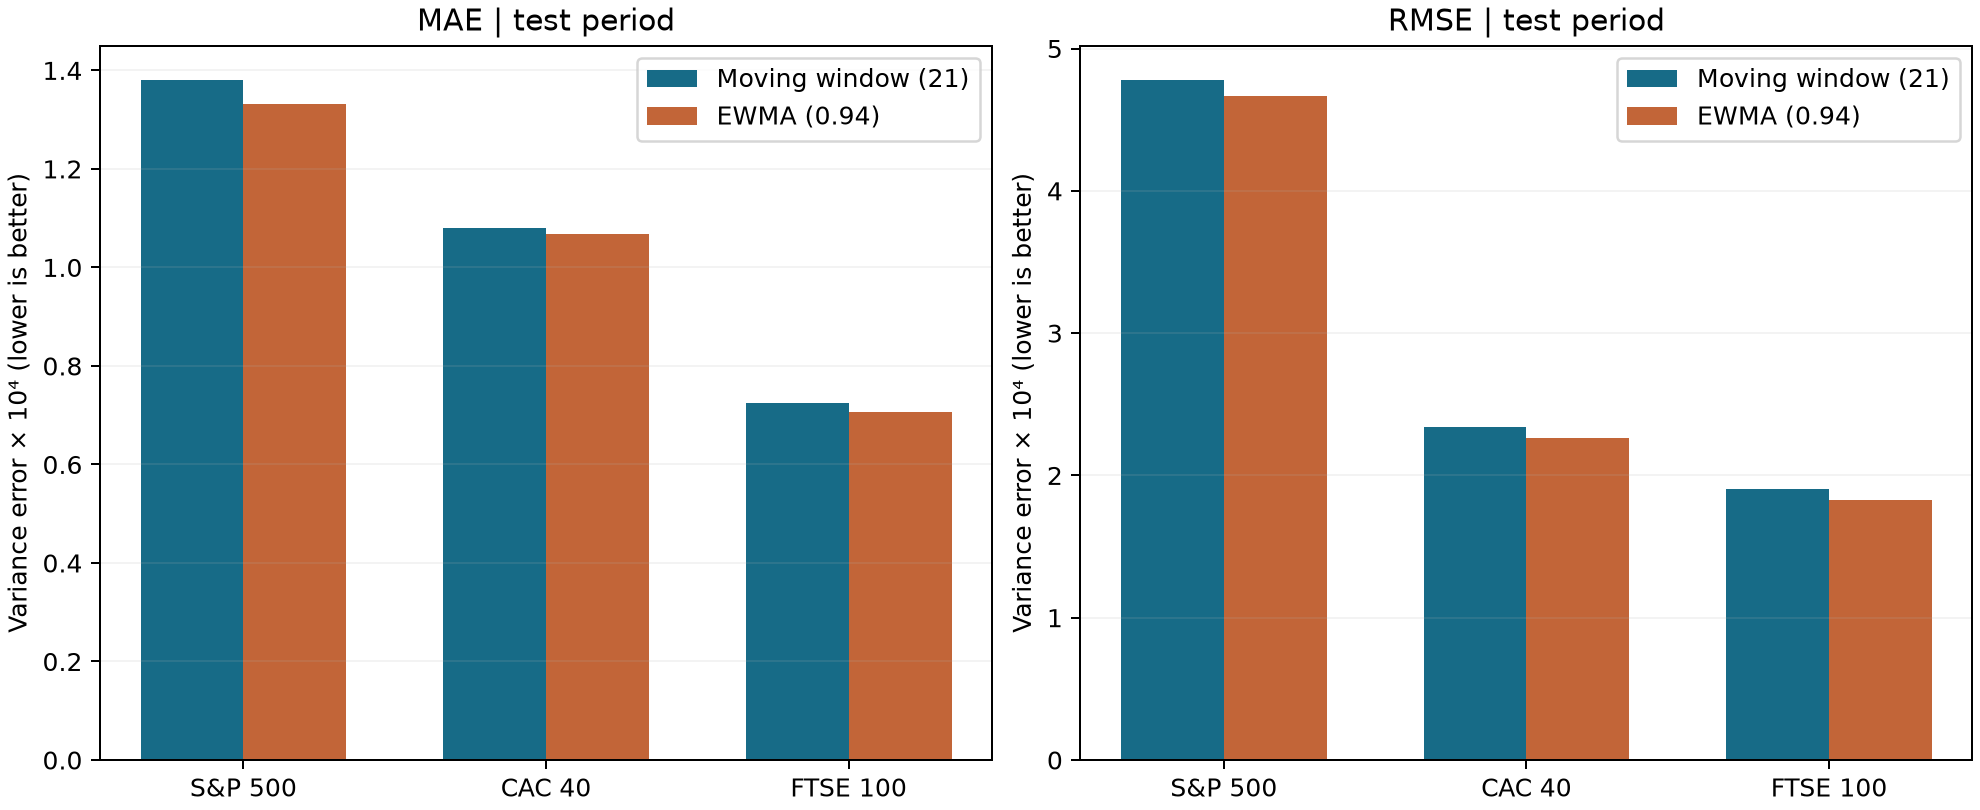

In [5]:
display(Image(filename=str(ROOT / 'reports/figures/phase5_test_errors.png')))

In [6]:
comparison = pd.read_csv(ROOT / 'reports/phase5_comparison.csv')
comparison.loc[comparison.period=='test']

,index,period,metric,lower_loss_model,ewma_change_vs_moving_window_percent
2,S&P 500,test,mae,EWMA (0.94),-3.538701
3,S&P 500,test,rmse,EWMA (0.94),-2.490327
6,CAC 40,test,mae,EWMA (0.94),-1.064710
7,CAC 40,test,rmse,EWMA (0.94),-3.259793
10,FTSE 100,test,mae,EWMA (0.94),-2.629181
11,FTSE 100,test,rmse,EWMA (0.94),-4.056104


Les variations négatives de la dernière colonne correspondent à une erreur plus faible pour l’EWMA. Les réductions observées en test sont d’environ 1 à 4 %. Aucun test de significativité n’a été réalisé ; la conclusion reste limitée à cette comparaison.

## 5. Exclusion des cibles manquantes

Une prévision produite avant de connaître une observation manquante est conservée, mais exclue du calcul des scores lorsque sa cible est indisponible.

In [7]:
ftse = pd.read_csv(ROOT / 'data/evaluation/ftse100_evaluation.csv', index_col='target_date', parse_dates=True)
ftse.loc['2020-12-21':'2020-12-24', ['target_squared_return', 'moving_window_variance', 'ewma_variance', 'eligible', 'exclusion_reason']]

,target_squared_return,moving_window_variance,ewma_variance,eligible,exclusion_reason
target_date,,,,,
2020-12-21,3.042533e-04,0.000066,0.000096,True,NaN
2020-12-22,NaN,0.000080,0.000108,False,Missing daily target return
2020-12-23,NaN,NaN,NaN,False,Missing daily target return
2020-12-24,9.397994e-07,NaN,NaN,False,Unavailable forecast
